# 02 · Forecasting Total Demand — Baselines vs ARIMA vs ETS vs Prophet vs Machine Learning
**Author: Anurag Moyal**

**Goal.** Forecast the next **90 days** of total daily unit sales and find out which model family is genuinely best —
judged by **rolling-origin backtesting** (four non-overlapping 90-day windows), not by one lucky split.

| # | Model | Family | Why it is here |
|---|---|---|---|
| 1 | Naive (last 28-day mean) | baseline | The "do nothing" benchmark |
| 2 | Seasonal naive (repeat last week) | baseline | Captures the weekly cycle only |
| 3 | Seasonal naive YoY × growth | baseline | Repeat last year's shape, scaled by recent growth — a hard-to-beat business rule |
| 4 | ETS (Holt-Winters, damped trend, weekly seasonality) | statistical | Classic exponential smoothing |
| 5 | SARIMAX (log scale, weekly SARMA + annual Fourier terms) | statistical | ARIMA that can see *both* seasonalities |
| 6 | Prophet | additive/multiplicative regression | Industry-standard trend + multi-season model |
| 7 | LightGBM with lag features (direct multi-horizon) | machine learning | Gradient boosting on lags, rolling means, calendar |

**Metrics.** MAPE, RMSE (the two the brief asks for), plus WAPE, MAE and MASE (scale-free vs seasonal-naive) for robustness.

In [1]:
import logging, time, warnings
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy.stats import norm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from forecast_utils import metrics, mase, rolling_origins, build_rows, FEATURES

warnings.filterwarnings("ignore"); logging.getLogger("cmdstanpy").setLevel(logging.ERROR); logging.getLogger("prophet").setLevel(logging.ERROR)
FIG, REP, PROC = ROOT / "reports/figures", ROOT / "reports", ROOT / "data/processed"
sns.set_theme(style="whitegrid")
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2F5D8A", "#E08A2E", "#2E8B57", "#C0392B", "#8A8F98", "#7A6FAC"
def save(n): plt.tight_layout(); plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight"); plt.show()

tot = pd.read_csv(PROC / "total_daily_sales.csv", index_col=0, parse_dates=True).iloc[:, 0].asfreq("D")
dates, y = tot.index, tot.values.astype(float)
H, N_FOLDS = 90, 4
folds = rolling_origins(dates, H, N_FOLDS)
for i, (te_, ts, tend) in enumerate(folds, 1):
    print(f"Fold {i}: train {dates[0].date()} → {dates[te_].date()} ({te_+1:,} days) · test {dates[ts].date()} → {dates[tend].date()}")

Importing plotly failed. Interactive plots will not work.


Fold 1: train 2013-01-01 → 2017-01-05 (1,466 days) · test 2017-01-06 → 2017-04-05
Fold 2: train 2013-01-01 → 2017-04-05 (1,556 days) · test 2017-04-06 → 2017-07-04
Fold 3: train 2013-01-01 → 2017-07-04 (1,646 days) · test 2017-07-05 → 2017-10-02
Fold 4: train 2013-01-01 → 2017-10-02 (1,736 days) · test 2017-10-03 → 2017-12-31


## 1. Model definitions
Every function takes only the *training* history and returns exactly `H` forecasts — nothing from the test window can leak in.

In [2]:
def f_naive(tr, h=H):           return np.full(h, tr[-28:].mean())
def f_snaive(tr, h=H):          return np.tile(tr[-7:], int(np.ceil(h / 7)))[:h]
def f_snaive_yoy(tr, h=H):
    n = len(tr); growth = tr[-91:].mean() / tr[-364 - 91: -364].mean()
    idx = np.arange(n, n + h) - 364                                # 364 = 52 weeks: same weekday one year earlier
    return tr[idx] * growth
def f_ets(tr, h=H):
    m = ExponentialSmoothing(tr[-1095:], trend="add", damped_trend=True, seasonal="mul", seasonal_periods=7, initialization_method="estimated").fit()
    return m.forecast(h)

def fourier(index, K=4, period=365.25):
    t = np.asarray(index.dayofyear)
    return np.column_stack([f(2 * np.pi * k * t / period) for k in range(1, K + 1) for f in (np.sin, np.cos)])
def f_sarimax(tr_s, h=H):
    X, Xf = fourier(tr_s.index), fourier(pd.date_range(tr_s.index[-1] + pd.Timedelta(days=1), periods=h))
    m = SARIMAX(np.log(tr_s.values), exog=X, order=(1, 1, 1), seasonal_order=(1, 0, 1, 7), trend="n").fit(disp=False, maxiter=150)
    return np.exp(m.forecast(h, exog=Xf))
def f_prophet(tr_s, h=H):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False, seasonality_mode="multiplicative", changepoint_prior_scale=0.05)
    m.fit(pd.DataFrame({"ds": tr_s.index, "y": tr_s.values}))
    return m.predict(m.make_future_dataframe(h))["yhat"].values[-h:]

LGB_FEATS = [f for f in FEATURES if f not in ("store", "item")]
def f_lgbm(tr, end_idx, h=H):
    S = y[:, None]
    tr_rows = build_rows(S, dates, range(372, end_idx + 1, 2), h, cutoff=end_idx)
    mdl = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.04, num_leaves=31, min_child_samples=40, subsample=.8, subsample_freq=1,
                            colsample_bytree=.8, verbose=-1, n_jobs=-1, random_state=42)
    mdl.fit(tr_rows[LGB_FEATS], tr_rows.y / tr_rows.m91)
    te_rows = build_rows(S, dates, [end_idx], h, with_target=False)
    return mdl.predict(te_rows[LGB_FEATS]) * te_rows.m91.values

## 2. Rolling-origin backtest (4 folds × 90 days)

In [3]:
MODELS = ["Naive (28-day mean)", "Seasonal naive (7)", "Seasonal naive YoY×growth", "ETS (Holt-Winters)", "SARIMAX (annual Fourier)", "Prophet", "LightGBM (lag features)"]
fc, truth, rows, timing = {m: [] for m in MODELS}, [], [], {m: 0.0 for m in MODELS}
for k, (tr_end, ts, te_end) in enumerate(folds, 1):
    tr, tr_s, act = y[: tr_end + 1], tot.iloc[: tr_end + 1], y[ts: te_end + 1]
    truth.append(act)
    runs = {"Naive (28-day mean)": lambda: f_naive(tr), "Seasonal naive (7)": lambda: f_snaive(tr),
            "Seasonal naive YoY×growth": lambda: f_snaive_yoy(tr), "ETS (Holt-Winters)": lambda: f_ets(tr),
            "SARIMAX (annual Fourier)": lambda: f_sarimax(tr_s), "Prophet": lambda: f_prophet(tr_s), "LightGBM (lag features)": lambda: f_lgbm(tr, tr_end)}
    for name, fn in runs.items():
        t0 = time.time(); p = np.asarray(fn(), float); timing[name] += time.time() - t0
        fc[name].append(p); rows.append(dict(fold=k, model=name, MASE=mase(act, p, tr), **metrics(act, p)))
    print(f"fold {k} done")
res = pd.DataFrame(rows)
summary = res.groupby("model")[["MAPE", "RMSE", "WAPE", "MAE", "MASE", "Bias"]].mean().loc[MODELS]
summary["MAPE_std"] = res.groupby("model").MAPE.std().loc[MODELS]
summary["fit+predict s/fold"] = pd.Series(timing).loc[MODELS] / N_FOLDS
summary.round(2).style.format("{:.2f}").background_gradient(cmap="Greens_r", subset=["MAPE", "RMSE", "WAPE", "MASE"])

11:53:00 - cmdstanpy - INFO - Chain [1] start processing


11:53:01 - cmdstanpy - INFO - Chain [1] done processing


fold 1 done


11:53:44 - cmdstanpy - INFO - Chain [1] start processing


11:53:45 - cmdstanpy - INFO - Chain [1] done processing


...

fold 3 done


11:56:00 - cmdstanpy - INFO - Chain [1] start processing


11:56:01 - cmdstanpy - INFO - Chain [1] done processing


fold 4 done


,MAPE,RMSE,WAPE,MAE,MASE,Bias,MAPE_std,fit+predict s/fold
model,,,,,,,,
Naive (28-day mean),17.29,6073.90,16.89,4977.36,6.42,-2.54,3.14,0.00
Seasonal naive (7),12.84,4718.34,12.61,3667.85,4.74,-1.24,1.89,0.00
Seasonal naive YoY×growth,2.16,914.44,2.15,568.49,0.74,1.06,2.20,0.00
ETS (Holt-Winters),12.27,4484.48,12.15,3496.10,4.52,-1.52,2.91,0.33
SARIMAX (annual Fourier),4.37,1510.69,4.31,1228.99,1.59,1.70,1.50,12.88
Prophet,3.90,1374.10,3.88,1090.76,1.41,0.44,1.52,1.20
LightGBM (lag features),3.27,1065.99,3.18,868.21,1.12,1.76,2.11,52.04


**How to read it.** (MASE is scaled by the *in-sample* weekly-naive error, which is tiny here because the weekly pattern is so regular, so even good models score above 1 — compare models with each other, not with 1.)

**Metrics:** MAPE/WAPE are % errors (lower is better). RMSE is in units/day. MASE < 1 means better than the in-sample
seasonal-naive. `Bias` > 0 means the model over-forecasts (stock-out risk is lower, over-stock risk higher).

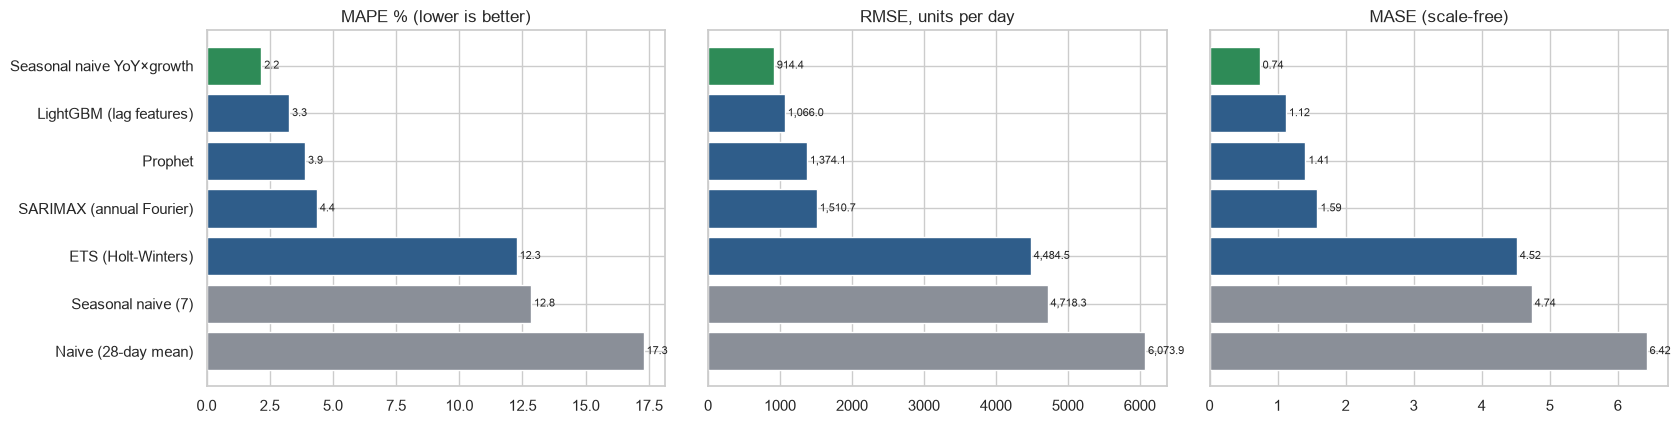

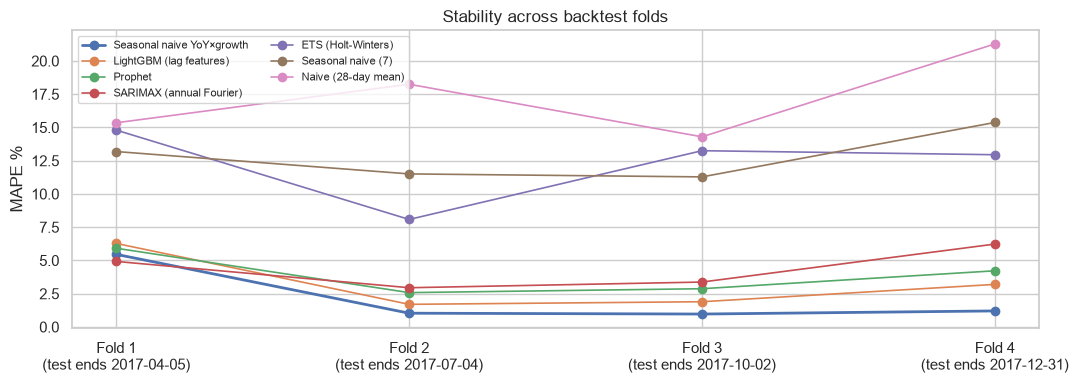

In [4]:
order = summary.sort_values("MAPE").index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
cols = [GREEN if m == order[0] else BLUE if "naive" not in m.lower() else GREY for m in order]
for a, (c, t) in zip(ax, [("MAPE", "MAPE % (lower is better)"), ("RMSE", "RMSE, units per day"), ("MASE", "MASE (scale-free)")]):
    s = summary.loc[order, c]; a.barh(order[::-1], s.values[::-1], color=cols[::-1]); a.set_title(t)
    for i, v in enumerate(s.values[::-1]): a.text(v, i, f" {v:,.1f}" if c != "MASE" else f" {v:.2f}", va="center", fontsize=8)
ax[1].set_yticklabels([]); ax[2].set_yticklabels([])
save("07_model_comparison")

fig, ax = plt.subplots(figsize=(11, 4))
piv = res.pivot(index="fold", columns="model", values="MAPE")[order]
for m in order: ax.plot(piv.index, piv[m], marker="o", label=m, lw=2 if m == order[0] else 1.2)
ax.set_xticks(piv.index); ax.set_xticklabels([f"Fold {i}\n(test ends {dates[f[2]].date()})" for i, f in zip(piv.index, folds)])
ax.set_ylabel("MAPE %"); ax.set_title("Stability across backtest folds"); ax.legend(fontsize=8, ncol=2)
save("08_fold_stability")

## 3. What do the forecasts look like? (final 90-day window)

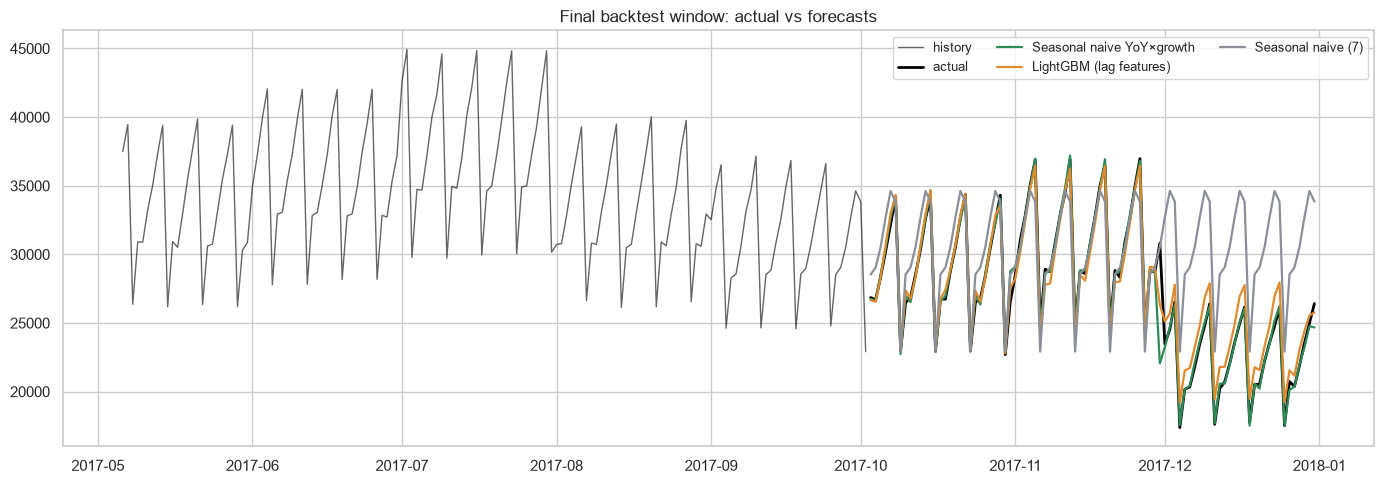

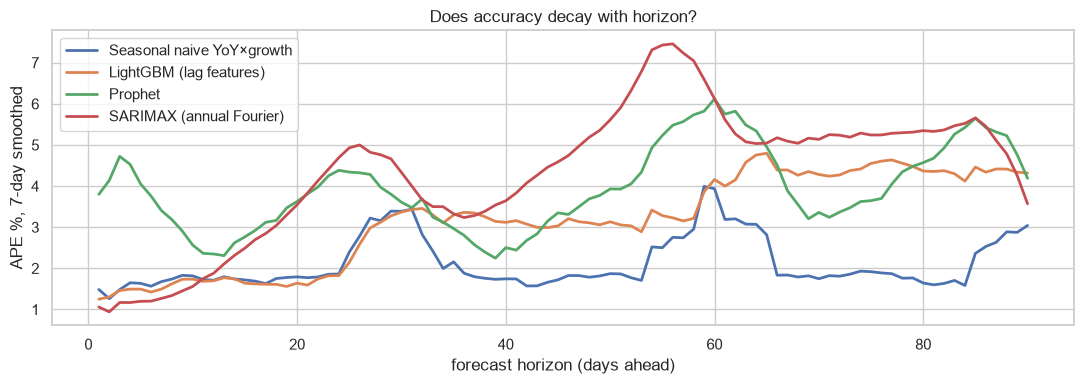

In [5]:
last = len(folds) - 1
test_dates = dates[folds[last][1]: folds[last][2] + 1]
show = [order[0], order[1], "Seasonal naive (7)", "Seasonal naive YoY×growth"]
show = list(dict.fromkeys(show))
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dates[-240:-H], y[-240:-H], color="black", lw=1, alpha=.6, label="history")
ax.plot(test_dates, truth[last], color="black", lw=2, label="actual")
for m, c in zip(show, [GREEN, ORANGE, GREY, PURPLE]): ax.plot(test_dates, fc[m][last], lw=1.6, label=m, color=c)
ax.set_title("Final backtest window: actual vs forecasts"); ax.legend(ncol=3, fontsize=9)
save("09_final_window_forecast")

# error by forecast horizon
fig, ax = plt.subplots(figsize=(11, 4))
hz = np.arange(1, H + 1)
for m in order[:4]:
    ape = np.mean([np.abs(fc[m][i] - truth[i]) / truth[i] * 100 for i in range(N_FOLDS)], axis=0)
    ax.plot(hz, pd.Series(ape).rolling(7, min_periods=1).mean(), label=m, lw=2)
ax.set_xlabel("forecast horizon (days ahead)"); ax.set_ylabel("APE %, 7-day smoothed"); ax.set_title("Does accuracy decay with horizon?"); ax.legend()
save("10_error_by_horizon")

## 4. Is the winner *significantly* better? (Diebold–Mariano)
Pooled squared errors of the best model vs each competitor; a small p-value means the difference is unlikely to be luck.
(Approximate: Newey–West variance with 14 lags on the concatenated folds.)

In [6]:
def dm(e1, e2, lags=14):
    d = e1**2 - e2**2; n = len(d); dc = d - d.mean()
    var = dc @ dc / n + 2 * sum((1 - k / (lags + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, lags + 1))
    stat = d.mean() / np.sqrt(var / n); return stat, 2 * (1 - norm.cdf(abs(stat)))
best = order[0]; cat = lambda m: np.concatenate([fc[m][i] - truth[i] for i in range(N_FOLDS)])
dmr = pd.DataFrame([dict(competitor=m, DM_stat=dm(cat(best), cat(m))[0], p_value=dm(cat(best), cat(m))[1]) for m in order[1:]]).set_index("competitor")
print(f"Best model by MAPE: {best}"); dmr.style.format({"DM_stat": "{:.2f}", "p_value": "{:.4f}"})

Best model by MAPE: Seasonal naive YoY×growth


,DM_stat,p_value
competitor,,
LightGBM (lag features),-1.45,0.1477
Prophet,-4.93,0.0000
SARIMAX (annual Fourier),-3.29,0.0010
ETS (Holt-Winters),-5.03,0.0000
Seasonal naive (7),-5.37,0.0000
Naive (28-day mean),-7.41,0.0000


## 5. Residual check on the best statistical model
A good model leaves residuals that look like noise (no leftover pattern).

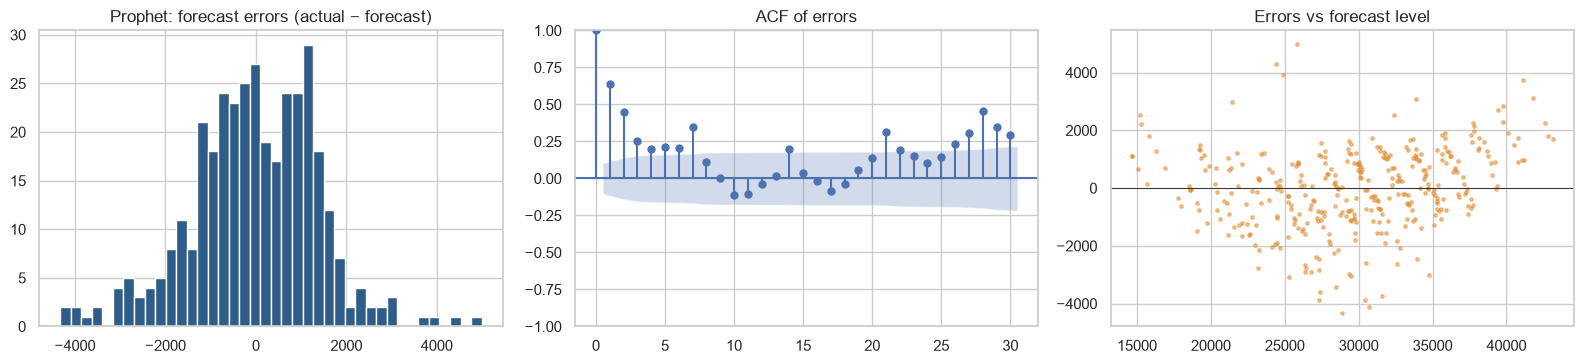

In [7]:
from statsmodels.graphics.tsaplots import plot_acf
stat_best = min(["ETS (Holt-Winters)", "SARIMAX (annual Fourier)", "Prophet"], key=lambda m: summary.loc[m, "MAPE"])
resid = np.concatenate([truth[i] - fc[stat_best][i] for i in range(N_FOLDS)])
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(resid, bins=40, color=BLUE); ax[0].set_title(f"{stat_best}: forecast errors (actual − forecast)")
plot_acf(resid, lags=30, ax=ax[1]); ax[1].set_title("ACF of errors")
ax[2].scatter(np.concatenate([fc[stat_best][i] for i in range(N_FOLDS)]), resid, s=6, alpha=.5, color=ORANGE); ax[2].axhline(0, color="k", lw=.6); ax[2].set_title("Errors vs forecast level")
save("11_residual_diagnostics")

## 6. Conclusions for total demand

In [8]:
ml = ["ETS (Holt-Winters)", "SARIMAX (annual Fourier)", "Prophet", "LightGBM (lag features)"]
best_ml = min(ml, key=lambda m: summary.loc[m, "MAPE"])
bm, b2, by = summary.loc[best], summary.loc["Seasonal naive (7)"], summary.loc["Seasonal naive YoY×growth"]
bml = summary.loc[best_ml]
print(f"""Best overall (lowest MAPE): {best} — MAPE {bm.MAPE:.2f}%, RMSE {bm.RMSE:,.0f} units/day, WAPE {bm.WAPE:.2f}%.
Best 'fitted' model: {best_ml} — MAPE {bml.MAPE:.2f}%, RMSE {bml.RMSE:,.0f}, WAPE {bml.WAPE:.2f}%.
Weekly seasonal-naive: MAPE {b2.MAPE:.1f}%  ·  YoY×growth rule: MAPE {by.MAPE:.2f}%.
→ {best_ml} cuts MAPE by {(1 - bml.MAPE / b2.MAPE) * 100:.0f}% vs weekly seasonal-naive, but {'beats' if bml.MAPE < by.MAPE else 'does NOT beat'} the YoY×growth rule at this aggregated level ({bml.MAPE:.2f}% vs {by.MAPE:.2f}%).
Reason: total demand has an extremely stable yearly shape, so "same weekday last year × growth" already captures almost everything; models that must
*learn* the shape from limited history (SARIMAX/Prophet/LightGBM) add estimation noise. The ML advantage appears at the noisy item level (notebook 03).
Ranking by MAPE: {' > '.join(order)}""")
summary.round(3).to_csv(REP / "results_total_level.csv")
res.round(3).to_csv(REP / "results_total_level_by_fold.csv", index=False)

Best overall (lowest MAPE): Seasonal naive YoY×growth — MAPE 2.16%, RMSE 914 units/day, WAPE 2.15%.
Best 'fitted' model: LightGBM (lag features) — MAPE 3.27%, RMSE 1,066, WAPE 3.18%.
Weekly seasonal-naive: MAPE 12.8%  ·  YoY×growth rule: MAPE 2.16%.
→ LightGBM (lag features) cuts MAPE by 75% vs weekly seasonal-naive, but does NOT beat the YoY×growth rule at this aggregated level (3.27% vs 2.16%).
Reason: total demand has an extremely stable yearly shape, so "same weekday last year × growth" already captures almost everything; models that must
*learn* the shape from limited history (SARIMAX/Prophet/LightGBM) add estimation noise. The ML advantage appears at the noisy item level (notebook 03).
Ranking by MAPE: Seasonal naive YoY×growth > LightGBM (lag features) > Prophet > SARIMAX (annual Fourier) > ETS (Holt-Winters) > Seasonal naive (7) > Naive (28-day mean)
